# CEE 902 · Multivariate Linear Regression with Gradient Descent

**Author:** Samuel Asiedu

**Goal:** Fit a multivariate linear regression model by batch gradient descent, tune the learning rate, evaluate the fit, and predict the price of a new house.

**Data:** An *illustrative* 15-house dataset with no documented real-world source, so it should not be presented as observed sales.

| Variable | Meaning | Unit |
|---|---|---|
| `size` | Floor area | ft² |
| `floors` | Number of floors | count |
| `age` | Age of the house | years |
| `price` | Sale price (target) | thousands of US dollars |

The three inputs are min-max normalized before fitting. The target `price` is left in its original units.

## 1. Setup and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

FEATURE_NAMES = ["Size (ft²)", "Floors", "Age (years)"]
TARGET_NAME = "Price ($1,000)"

size = np.array([4174, 4507, 1860, 2294, 2130, 2095, 4772, 4092, 2638, 3169,
                 1466, 2238, 1330, 2482, 3135], dtype=float)
floors = np.array([1, 3, 2, 1, 2, 2, 2, 2, 1, 1, 2, 2, 1, 1, 1], dtype=float)
age = np.array([90, 58, 41, 91, 59, 79, 14, 61, 61, 46, 61, 50, 54, 63, 2], dtype=float)
price = np.array([410, 540, 258, 212, 266, 244, 593, 457, 277, 352,
                  214, 320, 164, 281, 406], dtype=float)

# Raw feature matrix in original units: one row per house, one column per feature.
X_raw = np.column_stack([size, floors, age])
homes = pd.DataFrame(X_raw, columns=FEATURE_NAMES).assign(**{TARGET_NAME: price})
homes.describe().round(1)

,Size (ft²),Floors,Age (years),"Price ($1,000)"
count,15.0,15.0,15.0,15.0
mean,2825.5,1.6,55.3,332.9
std,1104.1,0.6,24.0,125.0
min,1330.0,1.0,2.0,164.0
25%,2112.5,1.0,48.0,251.0
50%,2482.0,2.0,59.0,281.0
75%,3630.5,2.0,62.0,408.0
max,4772.0,3.0,91.0,593.0


## 2. Min-max normalization and design matrix

Each feature is rescaled to the interval $[0, 1]$:

$$x_{\text{norm}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

The minimum and maximum of each feature are stored so that exactly the same scaling can be applied to new houses later. A column of ones ($x_0 = 1$) is added so that the intercept $\theta_0$ is handled by the same matrix product as the other coefficients.

In [2]:
feature_min = X_raw.min(axis=0)
feature_max = X_raw.max(axis=0)


def build_design_matrix(features_raw):
    # Scale raw features with the training min/max and prepend the intercept column.
    features_raw = np.atleast_2d(np.asarray(features_raw, dtype=float))
    features_norm = (features_raw - feature_min) / (feature_max - feature_min)
    return np.column_stack([np.ones(len(features_norm)), features_norm])


X = build_design_matrix(X_raw)
print("Design matrix shape:", X.shape)
print("First three rows:\n", np.round(X[:3], 3))

Design matrix shape: (15, 4)
First three rows:
 [[1.    0.826 0.    0.989]
 [1.    0.923 1.    0.629]
 [1.    0.154 0.5   0.438]]


## 3. Gradient descent

The model is $\hat{y} = X\theta$. The cost function is **half** the mean squared error:

$$J(\theta) = \frac{1}{2m}\sum_{i=1}^{m}\big(\hat{y}^{(i)} - y^{(i)}\big)^2,
\qquad
\nabla J(\theta) = \frac{1}{m}X^{\top}(X\theta - y),
\qquad
\theta := \theta - \alpha\,\nabla J(\theta)$$

Because $J$ is half the MSE, its numerical value is half of what a standard MSE routine would report.

In [3]:
def gradient_descent(X, y, learning_rate=0.01, iterations=10_000):
    # Batch gradient descent for linear regression.
    # Returns the fitted coefficients and the cost J (half MSE) at every iteration.
    m, n = X.shape                # m observations, n coefficients (including intercept)
    theta = np.zeros(n)
    cost_history = np.empty(iterations)

    for i in range(iterations):
        error = X @ theta - y                      # prediction error for every house
        cost_history[i] = (error @ error) / (2 * m)
        gradient = (X.T @ error) / m
        theta = theta - learning_rate * gradient   # simultaneous update of all coefficients

    return theta, cost_history

## 4. Exercise 1 · Explore the inputs and target

Price is plotted against each input in its original units. Because the raw arrays were never overwritten, no "un-scaling" step is needed.

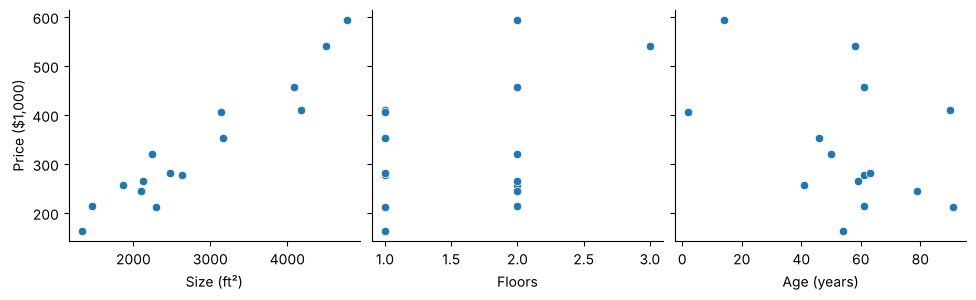

Pearson correlation with price:
Size (ft²)     0.95
Floors         0.39
Age (years)   -0.42
Name: Price ($1,000), dtype: float64


In [4]:
sns.pairplot(homes, x_vars=FEATURE_NAMES, y_vars=[TARGET_NAME], height=3, aspect=1.1)
plt.show()

print("Pearson correlation with price:")
print(homes.corr()[TARGET_NAME].drop(TARGET_NAME).round(2))

**Observations**

- **Size** has a strong, positive, approximately linear relationship with price.
- **Floors** is a *discrete* variable that takes only the values 1, 2, and 3, so the points form vertical bands. Only one house has three floors, which means the floors coefficient relies heavily on a single observation.
- **Age** shows a weak negative trend with considerable scatter.

## 5. Exercise 2 · Effect of the learning rate

Every run starts from zero coefficients and uses 10,000 iterations. Only the learning rate $\alpha$ changes.

In [5]:
ITERATIONS = 10_000
learning_rates = [0.0001, 0.001, 0.01, 0.1, 1.0, 1.1, 1.2, 1.3]

rate_results = []
cost_curves = {}
with np.errstate(over="ignore", invalid="ignore"):   # divergent runs overflow by design
    for rate in learning_rates:
        theta_trial, cost_trial = gradient_descent(X, price, rate, ITERATIONS)
        cost_curves[rate] = cost_trial
        rate_results.append({"learning_rate": rate,
                             "initial_J": cost_trial[0],
                             "final_J": cost_trial[-1]})

# The cost is quadratic, so gradient descent is stable only if alpha < 2 / lambda_max,
# where lambda_max is the largest eigenvalue of the Hessian X^T X / m.
hessian = X.T @ X / len(price)
stability_limit = 2 / np.linalg.eigvalsh(hessian).max()

print(f"Theoretical stability limit: learning rate < {stability_limit:.3f}\n")
print(pd.DataFrame(rate_results).to_string(index=False, float_format=lambda v: f"{v:.4g}"))

Theoretical stability limit: learning rate < 1.200

 learning_rate  initial_J  final_J
        0.0001  6.272e+04     6689
         0.001  6.272e+04      815
          0.01  6.272e+04    43.25
           0.1  6.272e+04    43.18
             1  6.272e+04    43.18
           1.1  6.272e+04    43.18
           1.2  6.272e+04 1.16e+07
           1.3  6.272e+04      NaN


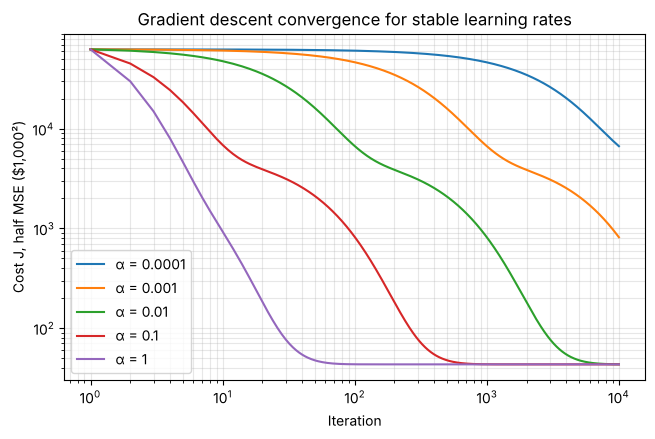

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for rate in [0.0001, 0.001, 0.01, 0.1, 1.0]:
    ax.plot(np.arange(1, ITERATIONS + 1), cost_curves[rate], label=f"α = {rate:g}")
ax.set(xscale="log", yscale="log", xlabel="Iteration",
       ylabel="Cost J, half MSE ($1,000²)",
       title="Gradient descent convergence for stable learning rates")
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.show()

**Findings**

- **Too slow:** $\alpha = 0.0001$ leaves the final cost at about 6,689, and $\alpha = 0.001$ (the original setting) still leaves it at about 815. Neither run has converged after 10,000 iterations.
- **Works well:** rates from about 0.01 up to 1.1 reach the minimum cost $J \approx 43.18$ within 10,000 iterations ($\alpha = 0.01$ is very close, at 43.25). A rate of 0.1 is a comfortable choice and is used for the final model.
- **Diverges:** for $\alpha \geq 1.2$ the cost *rises* at each iteration and eventually overflows to non-finite values (`inf` or `nan`). Each update overshoots the minimum by more than the previous error, so the coefficients move further away rather than closer.

The empirical threshold between 1.1 and 1.2 agrees with theory. For a quadratic cost, gradient descent is stable only when $\alpha < 2/\lambda_{\max}$, where $\lambda_{\max}$ is the largest eigenvalue of the Hessian $X^{\top}X/m$. For this dataset that limit is approximately 1.2.

## 6. Final model

The final model uses $\alpha = 0.1$. As a check, the coefficients are compared with the exact least-squares solution, which gradient descent should reproduce once it has converged.

In [7]:
FINAL_LEARNING_RATE = 0.1
theta, cost_history = gradient_descent(X, price, FINAL_LEARNING_RATE, ITERATIONS)
theta_exact, *_ = np.linalg.lstsq(X, price, rcond=None)

coefficients = pd.DataFrame(
    {"gradient_descent": theta, "exact_least_squares": theta_exact},
    index=["Intercept", "Size (normalized)", "Floors (normalized)", "Age (normalized)"])
print(coefficients.round(3))
print(f"\nFinal cost J (half MSE): {cost_history[-1]:.3f}")

                     gradient_descent  exact_least_squares
Intercept                     229.917              229.917
Size (normalized)             338.072              338.072
Floors (normalized)            69.699               69.699
Age (normalized)             -108.098             -108.098

Final cost J (half MSE): 43.181


## 7. Exercise 3 · Evaluate the fitted model

Residuals are defined as *actual minus predicted*.

Training MAE: $7.50 thousand


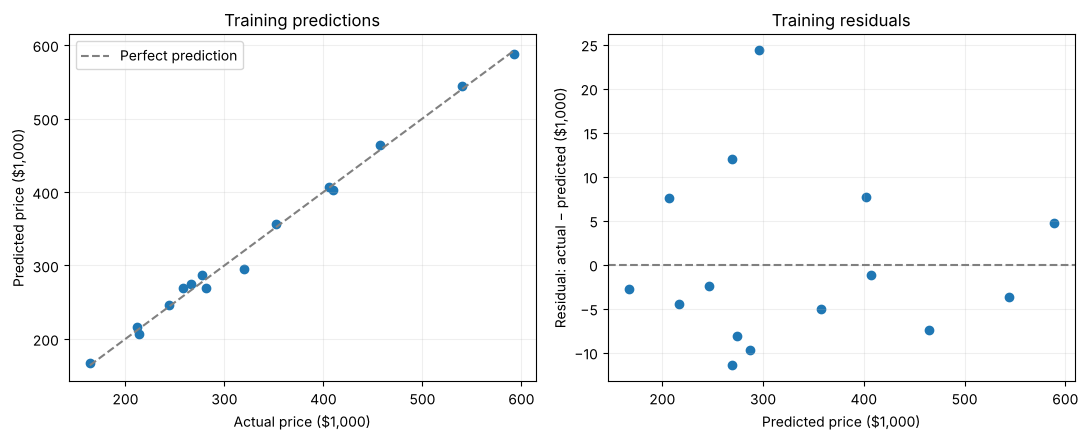

In [8]:
predictions = X @ theta
residuals = price - predictions
mae = np.mean(np.abs(residuals))
print(f"Training MAE: ${mae:.2f} thousand")

fig, (ax_fit, ax_res) = plt.subplots(1, 2, figsize=(11, 4.5))

limits = [min(price.min(), predictions.min()), max(price.max(), predictions.max())]
ax_fit.scatter(price, predictions)
ax_fit.plot(limits, limits, color="gray", linestyle="--", label="Perfect prediction")
ax_fit.set(xlabel="Actual price ($1,000)", ylabel="Predicted price ($1,000)",
           title="Training predictions")
ax_fit.legend()
ax_fit.grid(alpha=0.2)

ax_res.scatter(predictions, residuals)
ax_res.axhline(0, color="gray", linestyle="--")
ax_res.set(xlabel="Predicted price ($1,000)", ylabel="Residual: actual − predicted ($1,000)",
           title="Training residuals")
ax_res.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**Discussion**

- The residuals scatter around zero without an obvious curve or funnel shape, so there is no clear evidence against the linear form. With only 15 points, however, a real pattern would be difficult to detect.
- These results are **not** sufficient to claim that the model will predict new houses accurately. The MAE is computed on the same 15 houses used to fit four coefficients, so it measures training fit and is optimistic. A claim about new houses requires data that were held out from fitting (a test set or cross-validation).

## 8. Exercises 4 and 5 · Predict the price of a new house

The prediction steps are wrapped in a reusable function. It applies the **training** min-max constants to the new inputs before using the fitted coefficients.

In [9]:
def predict_house_price(size_sqft, num_floors, age_years):
    # Predicted price in thousands of US dollars for one house.
    x_new = build_design_matrix([size_sqft, num_floors, age_years])
    return float(x_new[0] @ theta)


x_example = build_design_matrix([3000, 2, 20])[0]
print("Normalized new house [1, size, floors, age]:", np.round(x_example, 3))
print(f"3,000 ft², 2 floors, 20 years: ${predict_house_price(3000, 2, 20):.1f} thousand")
print(f"2,500 ft², 1 floor, 30 years:  ${predict_house_price(2500, 1, 30):.1f} thousand")

Normalized new house [1, size, floors, age]: [1.    0.485 0.5   0.202]
3,000 ft², 2 floors, 20 years: $406.9 thousand
2,500 ft², 1 floor, 30 years:  $310.8 thousand


**Result:** the predicted price of the 3,000 ft², two-floor, 20-year-old house is about **\$406,900**.

Both example houses lie inside the range of the training data. Inputs outside that range (for example a 6,000 ft² house) map outside $[0, 1]$ after scaling, and the prediction becomes an extrapolation that the data cannot support.